In [2]:
#import the necessary Libraries
import pandas as pd
from sklearn.datasets import fetch_california_housing
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

In [3]:
# Load the dataset
housing = fetch_california_housing(as_frame=True)

# Convert to a DataFrame
df = housing.frame

# Display the first 5 rows
df.head()

print("Features:", housing.feature_names)
print("Target:", housing.target_names)

Features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
Target: ['MedHouseVal']


In [4]:
print("Dataset shape:", df.shape)

Dataset shape: (20640, 9)


In [5]:
# Check missing values in each column
df.isnull().sum()

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

In [6]:
#Check the data types and structure
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [7]:
#Check the statistical data
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


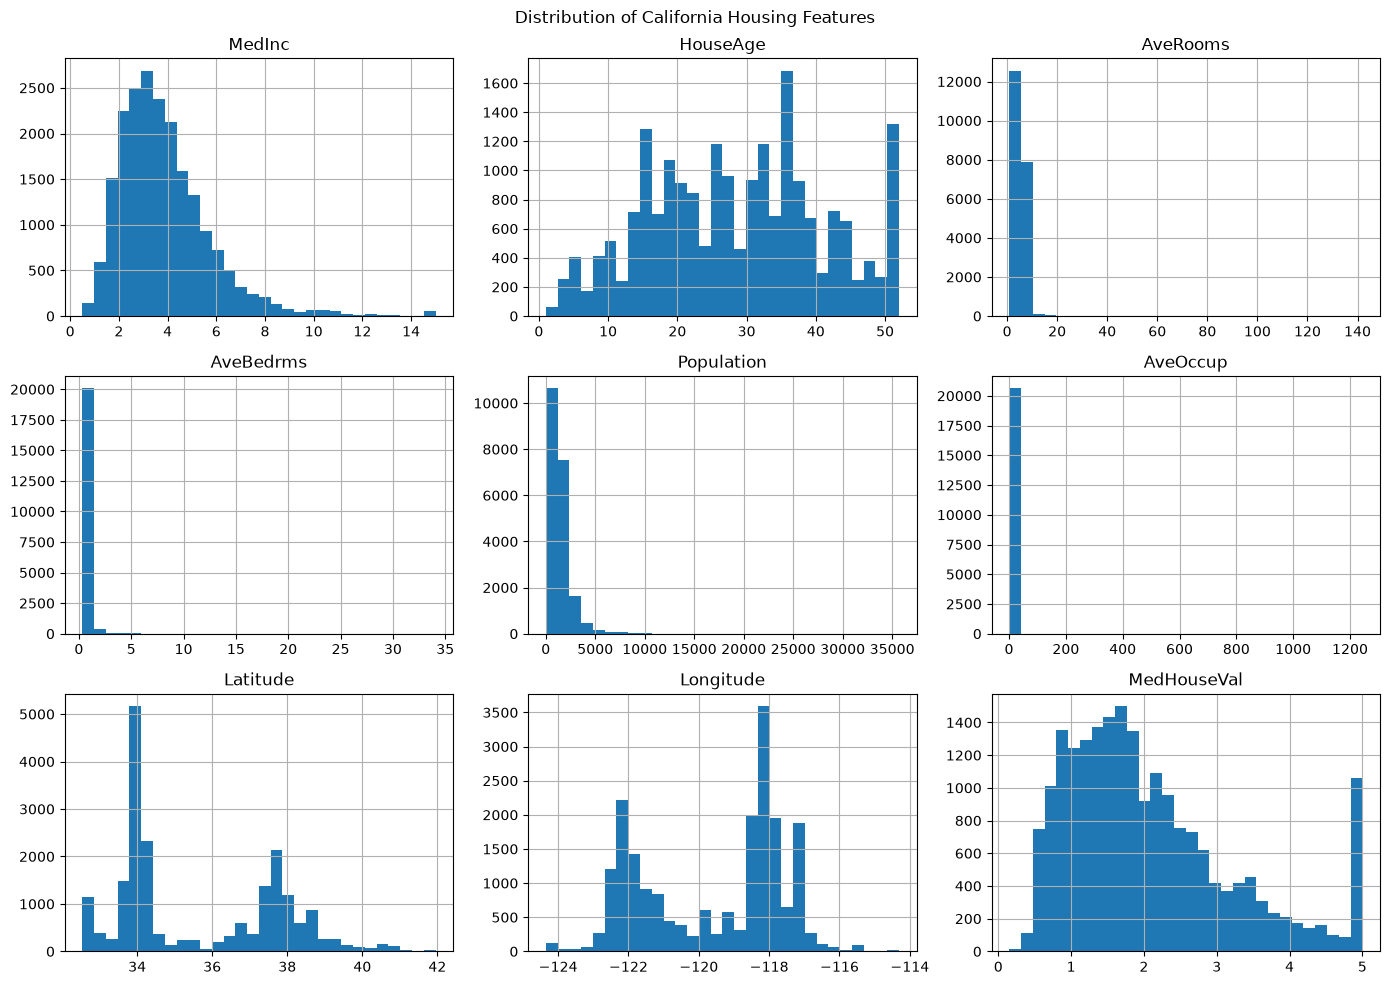

In [8]:
# Histograms for all features
df.hist(figsize=(14, 10), bins=30)

plt.suptitle("Distribution of California Housing Features")
plt.tight_layout()
plt.show()

The histograms help us understand how values are distributed across different housing features exampled
Median income and population appear right-skewed, meaning most districts have lower values, with fewer districts having very high values.
House age varies across districts with no definite right skewed, left skewed or normal distribution.
The average rooms, Average Bedrooms and occupancy have extreme values, located at a linear line.
The Median house valued is more right skewwed

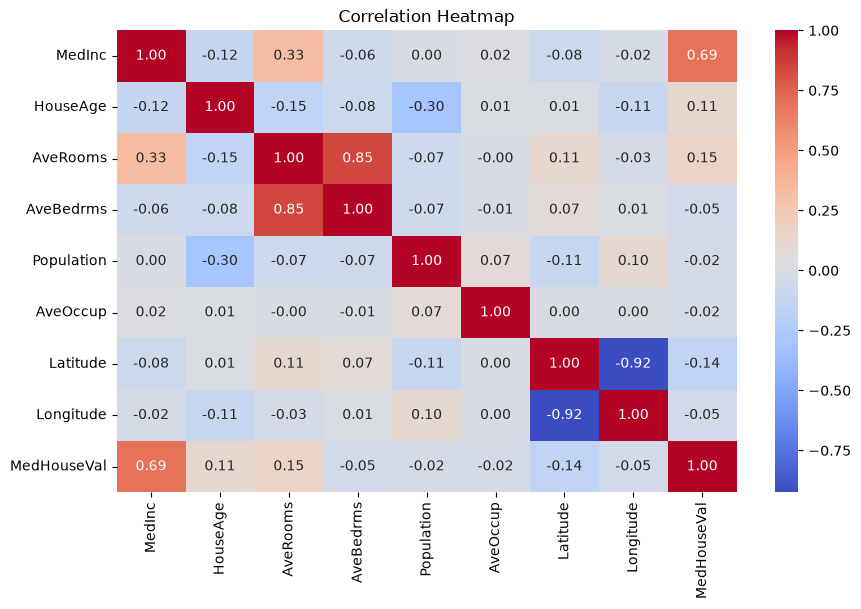

In [9]:
#Visualize relationships between features
plt.figure(figsize=(10, 6))

sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Heatmap")
plt.show()

All correlation closer to +1 indicates a strong positive relationship, while all correlation closer to -1 indicates a strong negative relationship.
The correlation heatmap shows how strongly different variables are related for example 
The MedInc and MedHouseVal indicate that higher household income is generally associated with higher median house values.

**Understand the Target Variable**

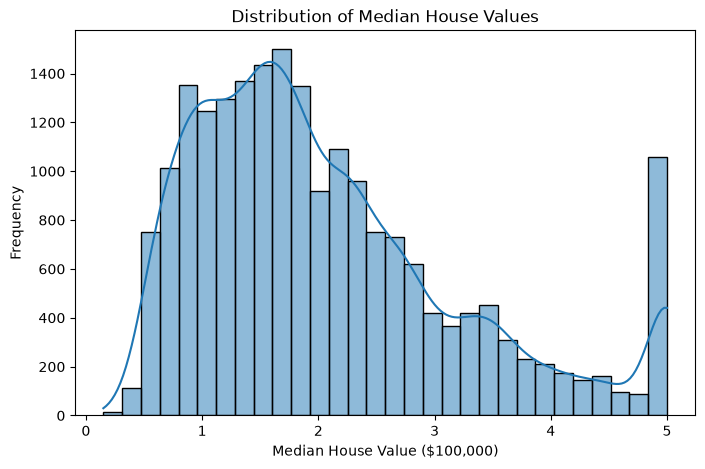

In [11]:
#Visualize the target variable distribution
plt.figure(figsize=(8, 5))

sns.histplot(df["MedHouseVal"], bins=30, kde=True)

plt.title("Distribution of Median House Values")
plt.xlabel("Median House Value ($100,000)")
plt.ylabel("Frequency")
plt.show()

The histogram shows that median house values in California are right-skewed meaning that most house prrices concentrate in the lower to middle price range. The average house value is approximately $206,856, which is higher than the median of $179,700, indicating that higher-priced districts pull the average upward.

**Split the Dataset into Training and Testing Sets**

In [12]:
# Features (X)
X = df.drop("MedHouseVal", axis=1)

# Target (y)
y = df["MedHouseVal"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

#Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42 # to ensure the split is reproducible
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Features shape: (20640, 8)
Target shape: (20640,)
Training features: (16512, 8)
Testing features: (4128, 8)
Training target: (16512,)
Testing target: (4128,)


The  data is split into 80% training data and 20% testing data

**key take-aways**
The California Housing dataset contains 20,640 observations with no missing values. The analysis shows that housing characteristics vary significantly across districts

Based on the visualizations specifically the correlation of the heatmap reveal positive and negative relationships between features.For example the average rooms and average bedrooms tend to have a positive relationship, while median income is positively associated with house values.

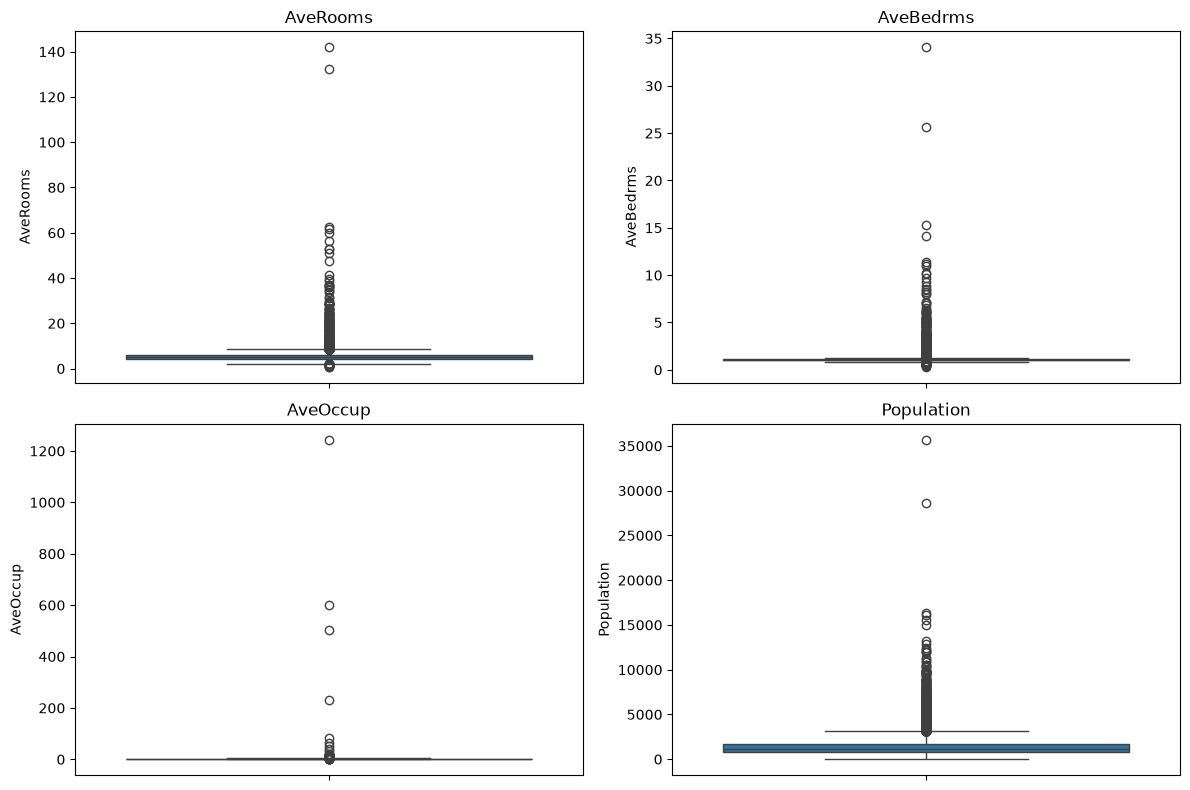

In [13]:
#Verifying outliers
features = ["AveRooms", "AveBedrms", "AveOccup", "Population"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, feature in zip(axes.flat, features):
    sns.boxplot(y=df[feature], ax=ax)
    ax.set_title(feature)

plt.tight_layout()
plt.show()

The descriptive statistics suggest significant outliers in average rooms, average bedrooms, average occupancy, and population. For example, average occupancy has a median of approximately 2.82 but a maximum of 1,243.33. Such extreme values may affect model training and should be investigated before deciding whether to remove or transform them.